In [2]:
import qiskit
from qiskit import QuantumCircuit

In [3]:
qiskit.__version__

'1.2.4'

In [ ]:
# Setup required packages (uncomment if running in cloud):
# %pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib

In [32]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import UnitaryGate
 
matrix = [[0, 0, 0, 1],
          [0, 0, 1, 0],
          [1, 0, 0, 0],
          [0, 1, 0, 0]]
gate = UnitaryGate(matrix)
 
circuit = QuantumCircuit(2)
circuit.append(gate, [0, 1])

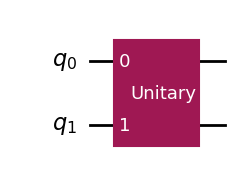

In [28]:
circuit.draw("mpl")

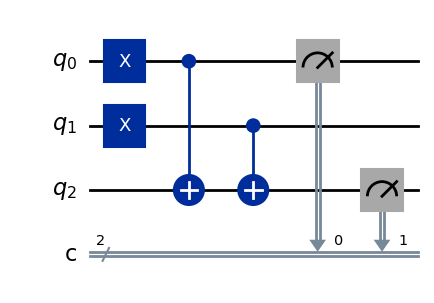

In [8]:
a=1
b=1
qc = QuantumCircuit(3, 2)

    # Set the input qubits based on the values of a and b
    #by defsult /0>
if a == 1:
     qc.x(0)  # Set qubit 0 to |1> if a is 1
if b == 1:
    qc.x(1)  # Set qubit 1 to |1> if b is 1

    # Sum calculation (XOR using CNOT gates)
qc.cx(0, 2)  # XOR between qubit 0 and auxiliary qubit 2
qc.cx(1, 2)  # XOR with the second input qubit

    # Measure the sum and carry
qc.measure(2, 1)  # Measure the sum into classical bit 1
qc.measure(0, 0)  # Measure carry into classical bit 0
qc.draw("mpl")

In [60]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Kraus, SuperOp
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
 
# Import from Qiskit Aer noise module
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)

In [62]:
# Construct a 1-qubit bit-flip and phase-flip errors
p_error = 0.05
bit_flip = pauli_error([('X', p_error), ('I', 1 - p_error)])
phase_flip = pauli_error([('Z', p_error), ('I', 1 - p_error)])
print(bit_flip)
print(phase_flip)

QuantumError on 1 qubits. Noise circuits:
  P(0) = 0.05, Circuit = 
   ┌───┐
q: ┤ X ├
   └───┘
  P(1) = 0.95, Circuit = 
   ┌───┐
q: ┤ I ├
   └───┘
QuantumError on 1 qubits. Noise circuits:
  P(0) = 0.05, Circuit = 
   ┌───┐
q: ┤ Z ├
   └───┘
  P(1) = 0.95, Circuit = 
   ┌───┐
q: ┤ I ├
   └───┘


In [64]:
# Compose two bit-flip and phase-flip errors
bitphase_flip = bit_flip.compose(phase_flip)
print(bitphase_flip)

QuantumError on 1 qubits. Noise circuits:
  P(0) = 0.0025000000000000005, Circuit = 
   ┌───┐┌───┐
q: ┤ X ├┤ Z ├
   └───┘└───┘
  P(1) = 0.0475, Circuit = 
   ┌───┐┌───┐
q: ┤ X ├┤ I ├
   └───┘└───┘
  P(2) = 0.0475, Circuit = 
   ┌───┐┌───┐
q: ┤ I ├┤ Z ├
   └───┘└───┘
  P(3) = 0.9025, Circuit = 
   ┌───┐┌───┐
q: ┤ I ├┤ I ├
   └───┘└───┘


In [66]:
# Convert to Kraus operator
bit_flip_kraus = Kraus(bit_flip)
print(bit_flip_kraus)

Kraus([[[ 9.74679434e-01+0.j,  0.00000000e+00+0.j],
        [ 0.00000000e+00+0.j,  9.74679434e-01+0.j]],

       [[ 0.00000000e+00+0.j,  2.23606798e-01+0.j],
        [ 2.23606798e-01+0.j, -4.96506831e-17+0.j]]],
      input_dims=(2,), output_dims=(2,))


In [68]:
# Convert to Superoperator
phase_flip_sop = SuperOp(phase_flip)
print(phase_flip_sop)

SuperOp([[1. +0.j, 0. +0.j, 0. +0.j, 0. +0.j],
         [0. +0.j, 0.9+0.j, 0. +0.j, 0. +0.j],
         [0. +0.j, 0. +0.j, 0.9+0.j, 0. +0.j],
         [0. +0.j, 0. +0.j, 0. +0.j, 1. +0.j]],
        input_dims=(2,), output_dims=(2,))


In [76]:
# Measurement misassignment probabilities
p0given1 = 0.1
p1given0 = 0.05
 
ReadoutError([[1 - p1given0, p1given0], [p0given1, 1 - p0given1]])

ReadoutError([[0.95 0.05]
 [0.1  0.9 ]])

In [72]:
# Custom Modelling 
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import EstimatorV2 as Estimator
 
service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False)
 
# Setting options during primitive initialization
estimator = Estimator(backend, options={"resilience_level": 2})

AccountNotFoundError: 'Unable to find account.'

Estimator also supports resilience_level. The resilience level specifies how much resilience to build against errors. Higher levels generate more accurate results, at the expense of longer processing times. Resilience levels can be used to configure the cost/accuracy trade-off when applying error mitigation to your primitive query. Error mitigation reduces errors (bias) in results by processing the outputs from a collection, or ensemble, of related circuits. The degree of error reduction depends on the method applied. The resilience level abstracts the detailed choice of error mitigation method to allow users to reason about the cost/accuracy trade that is appropriate to their application.

In [74]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import EstimatorV2 as Estimator
 
service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False)
 
estimator = Estimator(backend)
options = estimator.options
# Turn on gate twirling.
options.twirling.enable_gates = True
# Turn on measurement error mitigation.
options.resilience.measure_mitigation = True
 
print(f">>> gate twirling is turned on: {estimator.options.twirling.enable_gates}")
print(f">>> measurement error mitigation is turned on: {estimator.options.resilience.measure_mitigation}")

AccountNotFoundError: 'Unable to find account.'

In [ ]:
from qiskit import QuantumCircuit
qc = QuantumCircuit(2, 2)

qc.x(0)
qc.x(1)
qc.h(0)
qc.measure([0, 1], [0, 1])

qc.draw("mpl")